# Аналіз операційних даних марсіанської колонії "Ares VI" (2077+ рік)

**Виконавець:** Федорченко Юлія
**Група:** К-11
**Варіант:** №48

## 0. Початкове налаштування

In [32]:
# Комірка ТІЛЬКИ для виведення версій бібліотек
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sys

print(f"Python version: {sys.version.split()[0]}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Matplotlib version: {matplotlib.__version__}")

Python version: 3.12.6
Pandas version: 2.2.3
NumPy version: 2.2.3
Matplotlib version: 3.10.3


In [33]:
P_month = 48%12 + 1
data = pd.read_csv('ares_vi_log.csv', sep=',', encoding='utf-8')

### Попередня обробка даних
Підготуйте дані для аналізу: перетворіть типи колонок, обробіть текстові значення для отримання числових даних та створіть необхідні похідні колонки (за потреби).

In [34]:
for col in ["запас води", "запас їжі", "середній запас кисню", "згенеровано енергії",	"спожито енергії"]:
    data[col] = data[col].astype(str)
    data[col] = data[col].str.extract(r"([\d.]+)")
    data[col] = data[col].astype(float)


data["дата запису"] = pd.to_datetime(data["дата запису"])
data["населення колонії"] = data["населення колонії"].astype(int)


## 1. Динаміка ресурсів та енергії
Для періоду $P_{\text{місяць}}$ побудувати лінійні графіки зміни по днях числових значень: `"запасу води"`, `"запасу їжі"`, `"середнього запасу кисню"` (пропустити точки, де дані відсутні), та чистого енергобалансу. Графіки укласти на один рисунок (але не в один графік).

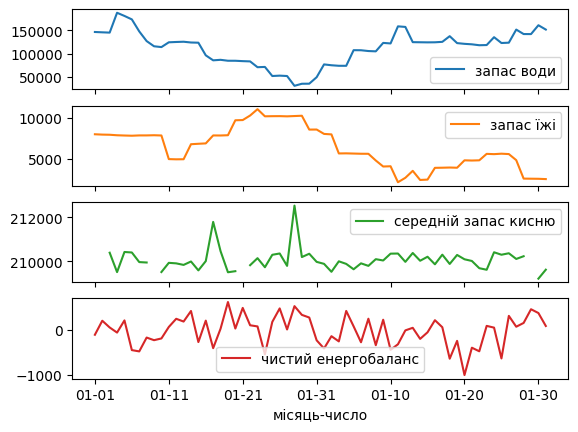

In [35]:

data["чистий енергобаланс"] = data["згенеровано енергії"] - data["спожито енергії"]

data["місяць-число"] = data["дата запису"].dt.strftime('%m-%d')
data_month = data[data["дата запису"].dt.month == P_month]
data_month.plot(x="місяць-число", y=["запас води", "запас їжі", "середній запас кисню", "чистий енергобаланс"], subplots=True, kind="line")
plt.show()



## 2. Залежність споживання енергії
Для періоду $P_{\text{місяць}}$ побудувати бульбашковий (scatter) графік залежності числового значення `"спожито енергії"` від `"населення колонії"`. Діаметр "бульбашки" має залежати від числового значення `"середнього запасу кисню"`. Якщо дані для `"середнього запасу кисню"` відсутні (значення "-"), використовувати для таких точок мінімальний фіксований діаметр.

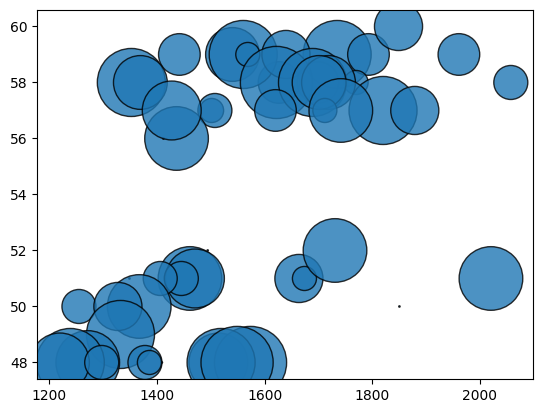

In [36]:
diams = np.where(data_month["середній запас кисню"].isna(), 1, (data_month["середній запас кисню"] % 10) * 300)

plt.scatter(data_month["спожито енергії"], data_month["населення колонії"], s = diams, edgecolors= "black", alpha = 0.8)
plt.show()


## 3. Середньомісячний енергобаланс
Знайти середньомісячне значення чистого енергобалансу (розрахованого в п.1 на основі числових значень).

In [37]:
data["рік-місяць"] = data["дата запису"].dt.to_period("M")
print(data.groupby("рік-місяць")[["чистий енергобаланс"]].mean())


            чистий енергобаланс
рік-місяць                     
2077-01               51.201613
2077-02              214.544643
2077-03              320.680645
2077-04              289.718333
2077-05               78.062258
2077-06               64.428000
2077-07             -172.481613
2077-08             -366.370323
2077-09             -397.821000
2077-10             -353.522258
2077-11             -434.781333
2077-12             -325.851613
2078-01              -94.970323
2078-02              -30.675000


## 4. Дні з мінімальним запасом їжі
Знайти всі дні (в межах усього періоду даних), коли фіксувалося найнижче числове значення `"запасу їжі"`. Вивести для цих днів усю наявну інформацію.

In [38]:
min = data[["дата запису","населення колонії","запас води","запас їжі","середній запас кисню","згенеровано енергії","спожито енергії"]].nsmallest(1, "запас їжі", keep = "all")
print(min)

    дата запису  населення колонії  запас води  запас їжі  \
230  2077-08-19                 53     56439.9     1055.5   

     середній запас кисню  згенеровано енергії  спожито енергії  
230              210144.0              1181.72          1958.67  


## 5. Дні найбільшого споживання енергії
У періоді $P_{\text{місяць}}$ знайти 4 дні з найбільшим числовим значенням `"спожито енергії"`. Вивести для них усю наявну інформацію.

In [39]:
max = data[["дата запису","населення колонії","запас води","запас їжі","середній запас кисню","згенеровано енергії","спожито енергії"]].nlargest(4, "спожито енергії", keep = "all")
print(max)

    дата запису  населення колонії  запас води  запас їжі  \
363  2077-12-30                 60     76818.3     8137.2   
386  2078-01-22                 58    117946.9     4829.0   
324  2077-11-21                 59     91457.2    11322.1   
128  2077-05-09                 53     99651.2    10972.4   

     середній запас кисню  згенеровано енергії  спожито енергії  
363                   NaN              1210.70          2141.28  
386              209692.0              1584.42          2057.81  
324              210319.0              1132.11          2053.83  
128              210354.0              1637.52          2023.16  


## 6. Дні енергетичного дефіциту
Знайти, скільки в кожному місяці було днів, коли чистий енергобаланс (на основі числових значень) був від'ємним. Побудувати кругову діаграму.

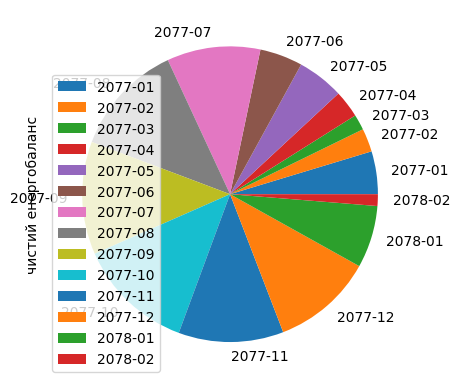

In [40]:
negative_energy_balance = data[data["чистий енергобаланс"]<0]

negative_energy_balance = negative_energy_balance.groupby("рік-місяць").count()
negative_energy_balance.plot(y = "чистий енергобаланс", kind = "pie")
plt.show()




## 7. Класифікація стану запасів води
Класифікувати стан запасів води на основі її числового значення: якщо числове значення `"запасу води"` > 100000, стан "Високий"; якщо <= 30000, стан "Низький"; у решті випадків – "Середній". 
Знайти кількість днів кожного стану на місяць та побудувати стовпчикову діаграму з накопиченням.

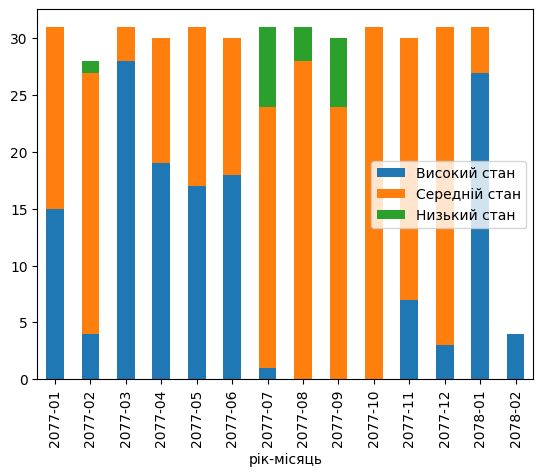

In [41]:
data["Високий стан"] = data["запас води"]>100000
data["Середній стан"] = (data["запас води"]>30000)&(data["запас води"]<=100000)
data["Низький стан"] = data["запас води"]<=30000

data.groupby("рік-місяць")[["Високий стан","Середній стан","Низький стан"]].sum().plot(y = ["Високий стан","Середній стан","Низький стан"], kind = "bar", stacked=True)
plt.show()

## 8. Порівняння енергозабезпечення та запасів води
Знайти всі місяці, в яких кількість днів з позитивним енергобалансом (числове значення `"згенеровано енергії"` > числового значення `"спожито енергії"`) була більшою, ніж кількість днів із "Низьким" станом запасів води (див. п.7).

In [42]:
data["Позитивний енергобаланс"] = data["чистий енергобаланс"]>0

comparison = data.groupby("рік-місяць")["Позитивний енергобаланс"].sum() > data.groupby("рік-місяць")["Низький стан"].sum()
print(f"Місяці, в яких к-сть днів з позитивним енергобалансом більше, ніж кількість днів із низьким станом запасів води: {comparison[comparison].index}")




Місяці, в яких к-сть днів з позитивним енергобалансом більше, ніж кількість днів із низьким станом запасів води: PeriodIndex(['2077-01', '2077-02', '2077-03', '2077-04', '2077-05', '2077-06',
             '2077-10', '2077-11', '2077-12', '2078-01', '2078-02'],
            dtype='period[M]', name='рік-місяць')


## 9. Розподіл енергобалансу
Побудувати гістограму щоденних значень чистого енергобалансу (розрахованого в п.1).

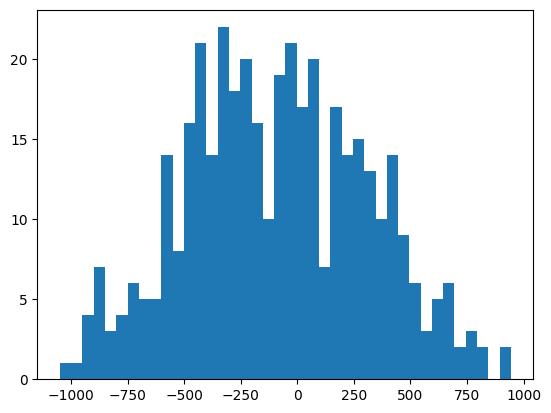

In [43]:
plt.hist(data["чистий енергобаланс"], bins = 40)
plt.show()